# Analisis dan Prediksi Employee Attrition Menggunakan Algoritma Machine Learning
**Dataset:** IBM HR Analytics Employee Attrition & Performance  
**Tahap:** UTS – Milestone 1

Notebook ini disusun dengan 10 komponen : perumusan masalah, pemahaman data, EDA, preprocessing, feature engineering, baseline, kandidat model, rancangan evaluasi, hasil awal, serta dokumentasi dan rencana lanjutan.

> **Catatan eksekusi:** notebook dijalankan dari atas ke bawah dengan file `WA_Fn-UseC_-HR-Employee-Attrition.csv`. Seluruh angka pada laporan berasal dari output sel kode.

## A. Problem Formulation (Bobot rubrik: 15)

### 1. Latar Belakang Masalah
Employee attrition merupakan kondisi ketika karyawan meninggalkan perusahaan. Tingginya attrition dapat memengaruhi stabilitas tenaga kerja, produktivitas, serta biaya perekrutan dan pelatihan karyawan baru.

Proyek ini menggunakan dataset IBM HR Analytics Employee Attrition & Performance untuk memahami karakteristik karyawan yang berkaitan dengan attrition dan membangun model klasifikasi yang memperkirakan apakah seorang karyawan termasuk kelas attrition.

### 2. Rumusan Masalah
1. Bagaimana karakteristik karyawan pada dataset IBM HR Analytics?
2. Fitur apa yang menunjukkan hubungan dengan attrition berdasarkan EDA?
3. Bagaimana menerapkan algoritma Machine Learning untuk memprediksi attrition?
4. Bagaimana mengevaluasi model pada data dengan kelas target yang tidak seimbang?
5. Model mana yang memberikan hasil awal terbaik berdasarkan F1-score, Recall, Precision, dan ROC-AUC?

### 3. Tujuan Penelitian

Tujuan dari proyek ini adalah:

1. Memahami karakteristik dan pola data karyawan berdasarkan dataset IBM HR Analytics.
2. Mengidentifikasi fitur-fitur yang berkaitan dengan employee attrition melalui proses EDA.
3. Melakukan preprocessing dan feature engineering untuk mempersiapkan data sebelum pemodelan.
4. Membangun dan membandingkan beberapa algoritma Machine Learning untuk memprediksi employee attrition.
5. Mengevaluasi performa model untuk menentukan algoritma yang paling sesuai dalam memprediksi employee attrition.
### 4. Target dan Batasan Proyek
- **Target:** kolom `Attrition`.
- **Kelas positif:** `Yes` (karyawan keluar), dikodekan menjadi 1.
- **Kelas negatif:** `No` (karyawan bertahan), dikodekan menjadi 0.
- **Jenis masalah:** klasifikasi biner.
- **Batasan Milestone 1:** eksperimen awal dan pemilihan kandidat; data test disimpan untuk evaluasi akhir setelah pemilihan model/tuning.

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    make_scorer, f1_score, recall_score, precision_score,
    confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

In [2]:
# Memuat dataset. Jika file belum tersedia di Google Colab, unggah saat diminta.
DATA_FILE = "WA_Fn-UseC_-HR-Employee-Attrition.csv"

if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files
        uploaded = files.upload()
    except ImportError:
        raise FileNotFoundError(
            f"File {DATA_FILE} tidak ditemukan. Letakkan file CSV di folder kerja notebook."
        )

df = pd.read_csv(DATA_FILE)
print("Ukuran dataset:", df.shape)
display(df.head())

Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition.csv
Ukuran dataset: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## B. Dataset dan Data Understanding (Bobot rubrik: 15)

### 1. Sumber dan deskripsi dataset
Dataset yang digunakan adalah **IBM HR Analytics Employee Attrition & Performance** dari Kaggle. Dataset berisi karakteristik demografis, pekerjaan, kompensasi, pengalaman, kepuasan, dan status attrition karyawan.

### 2. Struktur data
Tabel berikut menampilkan tipe data, jumlah nilai unik, jumlah missing value, dan contoh nilai pada setiap kolom.

In [3]:
info = pd.DataFrame({
    "Tipe data": df.dtypes.astype(str),
    "Jumlah nilai unik": df.nunique(),
    "Missing value": df.isna().sum(),
    "Contoh nilai": df.iloc[0]
})
display(info)
print("\nRingkasan tipe data:")
display(df.dtypes.value_counts().rename("Jumlah kolom").to_frame())

,Tipe data,Jumlah nilai unik,Missing value,Contoh nilai
Age,int64,43,0,41
Attrition,object,2,0,Yes
BusinessTravel,object,3,0,Travel_Rarely
DailyRate,int64,886,0,1102
Department,object,3,0,Sales
DistanceFromHome,int64,29,0,1
Education,int64,5,0,2
EducationField,object,6,0,Life Sciences
EmployeeCount,int64,1,0,1
EmployeeNumber,int64,1470,0,1



Ringkasan tipe data:


,Jumlah kolom
int64,26
object,9


### 3. Kamus fitur
Deskripsi di bawah merupakan ringkasan fungsi kolom berdasarkan nama dan nilai yang tersedia pada dataset. Untuk kolom tarif seperti `DailyRate`, `HourlyRate`, dan `MonthlyRate`, satuan atau definisi rinci tidak diasumsikan jika tidak dijelaskan oleh sumber dataset.

In [4]:
kamus = {
    "Age": ("Usia karyawan (tahun)", "Numerik"),
    "Attrition": ("Status karyawan keluar atau bertahan", "Target"),
    "BusinessTravel": ("Frekuensi perjalanan dinas", "Kategorikal"),
    "DailyRate": ("Tarif harian; definisi rinci tidak dijelaskan", "Numerik"),
    "Department": ("Departemen karyawan", "Kategorikal"),
    "DistanceFromHome": ("Jarak rumah ke tempat kerja; satuan tidak dijelaskan", "Numerik"),
    "Education": ("Tingkat pendidikan dengan skala 1–5", "Ordinal"),
    "EducationField": ("Bidang pendidikan", "Kategorikal"),
    "EmployeeCount": ("Jumlah karyawan; diperiksa apakah konstan", "Kandidat dibuang"),
    "EmployeeNumber": ("Nomor identitas karyawan", "Identitas; dibuang"),
    "EnvironmentSatisfaction": ("Kepuasan lingkungan kerja, skala 1–4", "Ordinal"),
    "Gender": ("Jenis kelamin", "Kategorikal"),
    "HourlyRate": ("Tarif per jam; definisi rinci tidak dijelaskan", "Numerik"),
    "JobInvolvement": ("Keterlibatan dalam pekerjaan, skala 1–4", "Ordinal"),
    "JobLevel": ("Level jabatan, skala 1–5", "Ordinal"),
    "JobRole": ("Peran pekerjaan", "Kategorikal"),
    "JobSatisfaction": ("Kepuasan kerja, skala 1–4", "Ordinal"),
    "MaritalStatus": ("Status pernikahan", "Kategorikal"),
    "MonthlyIncome": ("Pendapatan bulanan", "Numerik"),
    "MonthlyRate": ("Tarif bulanan; definisi rinci tidak dijelaskan", "Numerik"),
    "NumCompaniesWorked": ("Jumlah perusahaan tempat pernah bekerja", "Numerik"),
    "Over18": ("Indikator usia di atas 18 tahun", "Kandidat dibuang jika konstan"),
    "OverTime": ("Status kerja lembur", "Kategorikal"),
    "PercentSalaryHike": ("Persentase kenaikan gaji", "Numerik"),
    "PerformanceRating": ("Penilaian kinerja", "Ordinal"),
    "RelationshipSatisfaction": ("Kepuasan hubungan kerja, skala 1–4", "Ordinal"),
    "StandardHours": ("Jam kerja standar; diperiksa apakah konstan", "Kandidat dibuang"),
    "StockOptionLevel": ("Level opsi saham", "Ordinal"),
    "TotalWorkingYears": ("Total pengalaman kerja (tahun)", "Numerik"),
    "TrainingTimesLastYear": ("Jumlah pelatihan tahun lalu", "Numerik"),
    "WorkLifeBalance": ("Keseimbangan kerja dan kehidupan, skala 1–4", "Ordinal"),
    "YearsAtCompany": ("Lama bekerja di perusahaan (tahun)", "Numerik"),
    "YearsInCurrentRole": ("Lama pada peran saat ini (tahun)", "Numerik"),
    "YearsSinceLastPromotion": ("Lama sejak promosi terakhir (tahun)", "Numerik"),
    "YearsWithCurrManager": ("Lama bekerja dengan manajer saat ini (tahun)", "Numerik"),
}
kamus_df = pd.DataFrame(
    [(kolom, *kamus.get(kolom, ("Deskripsi perlu diverifikasi", "Belum diklasifikasikan")))
     for kolom in df.columns],
    columns=["Kolom", "Deskripsi", "Peran/jenis"]
)
display(kamus_df)

,Kolom,Deskripsi,Peran/jenis
0,Age,Usia karyawan (tahun),Numerik
1,Attrition,Status karyawan keluar atau bertahan,Target
2,BusinessTravel,Frekuensi perjalanan dinas,Kategorikal
3,DailyRate,Tarif harian; definisi rinci tidak dijelaskan,Numerik
4,Department,Departemen karyawan,Kategorikal
5,DistanceFromHome,Jarak rumah ke tempat kerja; satuan tidak dije...,Numerik
6,Education,Tingkat pendidikan dengan skala 1–5,Ordinal
7,EducationField,Bidang pendidikan,Kategorikal
8,EmployeeCount,Jumlah karyawan; diperiksa apakah konstan,Kandidat dibuang
9,EmployeeNumber,Nomor identitas karyawan,Identitas; dibuang


### 4. Pemeriksaan kualitas data awal
Pemeriksaan missing value, duplikat, kolom konstan, dan identitas dilakukan untuk memahami kondisi dataset. Pemeriksaan outlier dan skewness dilakukan setelah pembagian data dan hanya pada training.

In [5]:
print("Total missing value:", int(df.isna().sum().sum()))
print("Jumlah baris duplikat:", int(df.duplicated().sum()))

constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print("Kolom konstan:", constant_cols)

if "EmployeeNumber" in df.columns:
    print("EmployeeNumber unik:", df["EmployeeNumber"].is_unique)

print("Jumlah baris:", len(df))
print("Jumlah kolom:", df.shape[1])

Total missing value: 0
Jumlah baris duplikat: 0
Kolom konstan: ['EmployeeCount', 'Over18', 'StandardHours']
EmployeeNumber unik: True
Jumlah baris: 1470
Jumlah kolom: 35


## C. Exploratory Data Analysis / EDA (Bobot rubrik: 10)

EDA dilakukan pada data training agar pola yang digunakan untuk memahami data tidak mengambil informasi dari data test. Pembagian data dilakukan satu kali pada bagian D, sebelum grafik dan analisis EDA berikut dijalankan.

## D. Preprocessing dan pembagian data (Bobot rubrik: 10)

### 1. Menentukan fitur dan target
Kolom konstan dibuang karena tidak memberikan variasi informasi. `EmployeeNumber` dibuang karena merupakan identitas, bukan karakteristik prediktif. Target `Attrition` diubah menjadi 0 dan 1.

### 2. Pembagian data
Dilakukan satu kali dengan metode stratified hold-out 80:20. `stratify=y` menjaga proporsi kelas target pada data training dan testing. Data testing disimpan dan tidak digunakan untuk pemilihan model pada Milestone 1.

In [6]:
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
identity_cols = [c for c in ["EmployeeNumber"] if c in df.columns]
drop_cols = sorted(set(constant_cols + identity_cols + ["Attrition"]))

X = df.drop(columns=drop_cols)
y = (df["Attrition"].astype(str).str.strip().str.lower() == "yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

train = X_train.copy()
train["Attrition"] = y_train

print("Kolom yang dikeluarkan:", drop_cols)
print("Train:", X_train.shape, "| proporsi resign:", round(y_train.mean() * 100, 2), "%")
print("Test :", X_test.shape,  "| proporsi resign:", round(y_test.mean() * 100, 2), "%")
print("\nDistribusi target training:")
display(
    pd.DataFrame({
        "Jumlah": y_train.value_counts().rename(index={0: "No", 1: "Yes"}),
        "Persentase": (y_train.value_counts(normalize=True) * 100)
            .rename(index={0: "No", 1: "Yes"}).round(2)
    })
)

Kolom yang dikeluarkan: ['Attrition', 'EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours']
Train: (1176, 30) | proporsi resign: 16.16 %
Test : (294, 30) | proporsi resign: 15.99 %

Distribusi target training:


,Jumlah,Persentase
Attrition,,
No,986,83.84
Yes,190,16.16


### 3. Distribusi kelas target
Periksa apakah target tidak seimbang. Karena kelas `Yes` biasanya lebih sedikit, accuracy saja tidak cukup untuk menilai kemampuan mendeteksi karyawan yang resign.

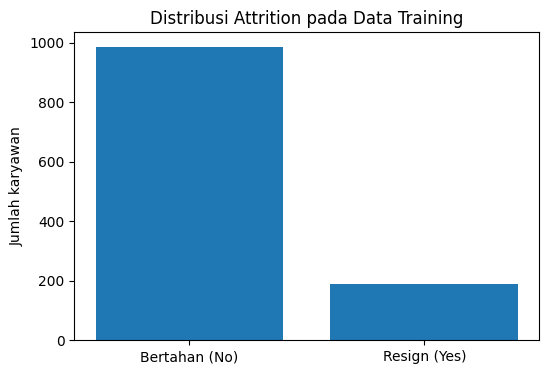

In [7]:
class_counts = y_train.value_counts().sort_index()
class_labels = ["Bertahan (No)", "Resign (Yes)"]
plt.figure(figsize=(6, 4))
plt.bar(class_labels, [class_counts.get(0, 0), class_counts.get(1, 0)])
plt.title("Distribusi Attrition pada Data Training")
plt.ylabel("Jumlah karyawan")
plt.show()

### 4. Hubungan fitur kategorikal dengan attrition
Persentase berikut adalah proporsi karyawan resign di setiap kategori. Jumlah sampel (`n`) ditampilkan agar kategori dengan anggota sedikit tidak ditafsirkan berlebihan.

In [8]:
categorical_eda = [
    c for c in ["OverTime", "MaritalStatus", "BusinessTravel",
                "Department", "JobRole", "Gender"]
    if c in X_train.columns
]
for col in categorical_eda:
    summary = train.groupby(col, dropna=False)["Attrition"].agg(
        jumlah="size", persen_resign="mean"
    )
    summary["persen_resign"] = (summary["persen_resign"] * 100).round(2)
    print(f"Attrition berdasarkan {col}")
    display(summary.sort_values("persen_resign", ascending=False))

Attrition berdasarkan OverTime


,jumlah,persen_resign
OverTime,,
Yes,340,28.53
No,836,11.12


Attrition berdasarkan MaritalStatus


,jumlah,persen_resign
MaritalStatus,,
Single,373,25.47
Married,540,12.22
Divorced,263,11.03


Attrition berdasarkan BusinessTravel


,jumlah,persen_resign
BusinessTravel,,
Travel_Frequently,225,25.33
Travel_Rarely,828,14.98
Non-Travel,123,7.32


... (2 outputs left out)

Attrition berdasarkan JobRole


,jumlah,persen_resign
JobRole,,
Sales Representative,60,41.67
Laboratory Technician,215,26.98
Human Resources,41,24.39
Sales Executive,273,17.95
Research Scientist,220,13.18
Manufacturing Director,113,6.19
Manager,83,6.02
Healthcare Representative,108,5.56
Research Director,63,1.59


Attrition berdasarkan Gender


,jumlah,persen_resign
Gender,,
Male,704,16.90
Female,472,15.04


### 5. Perbandingan fitur numerik
Boxplot membantu melihat perbedaan distribusi fitur numerik antara karyawan yang bertahan dan resign. Perbedaan visual tidak otomatis menunjukkan hubungan sebab-akibat.

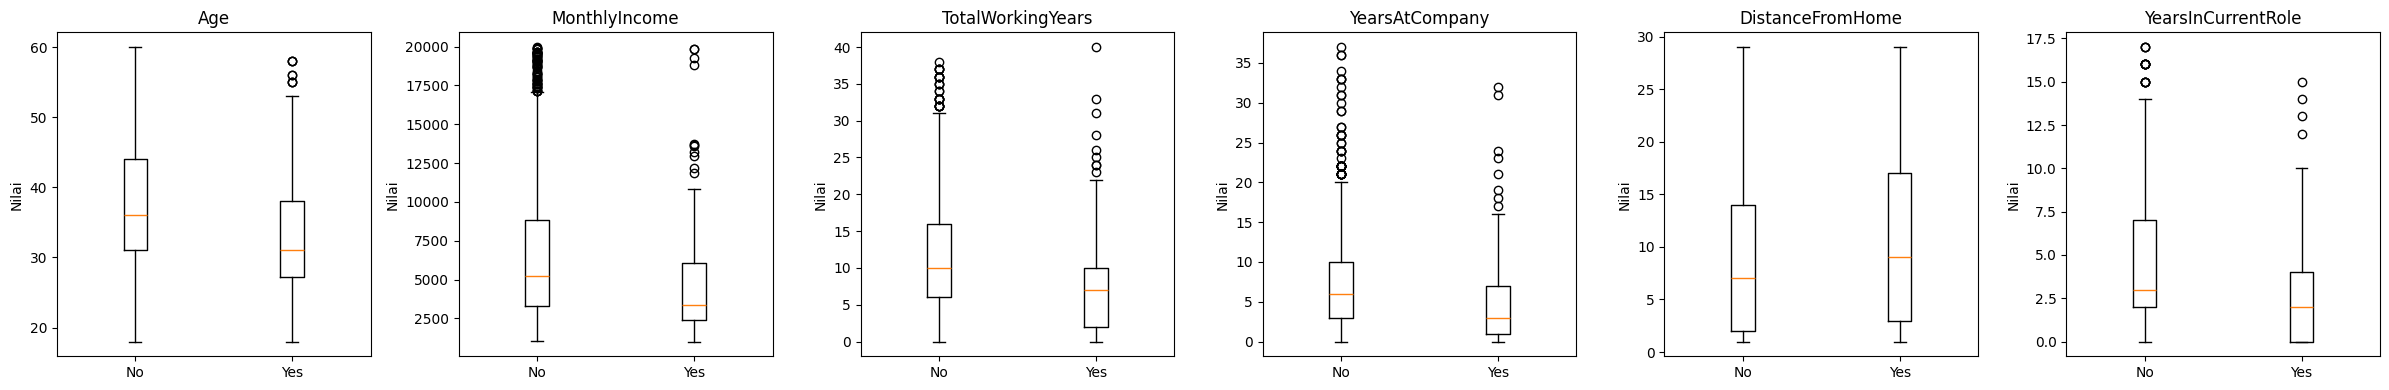

Attrition,0,1
Age,37.74,33.13
MonthlyIncome,6871.64,4843.88
TotalWorkingYears,12.00,8.06
YearsAtCompany,7.46,4.90
DistanceFromHome,9.05,10.97
YearsInCurrentRole,4.49,2.87


In [9]:
numeric_to_plot = [
    c for c in ["Age", "MonthlyIncome", "TotalWorkingYears",
                "YearsAtCompany", "DistanceFromHome", "YearsInCurrentRole"]
    if c in X_train.select_dtypes(include="number").columns
]
fig, axes = plt.subplots(1, len(numeric_to_plot), figsize=(4 * len(numeric_to_plot), 4))
if len(numeric_to_plot) == 1:
    axes = [axes]
for ax, col in zip(axes, numeric_to_plot):
    ax.boxplot(
        [train.loc[train["Attrition"] == 0, col].dropna(),
         train.loc[train["Attrition"] == 1, col].dropna()],
        labels=["No", "Yes"]
    )
    ax.set_title(col)
    ax.set_ylabel("Nilai")
plt.tight_layout()
plt.show()

display(train.groupby("Attrition")[numeric_to_plot].mean().T.round(2))

### 6. Outlier dan skewness pada data training

Deteksi IQR menandai nilai yang berada di luar rentang Q1 − 1,5×IQR dan Q3 + 1,5×IQR. Metode ini hanya diterapkan pada **fitur numerik kontinu** (lebih dari 10 nilai unik). Fitur ordinal atau diskret seperti `PerformanceRating` (hanya bernilai 3 dan 4), `StockOptionLevel`, dan skala kepuasan 1–4 **dikecualikan**, karena nilainya terbatas pada beberapa kategori sehingga konsep outlier IQR tidak berlaku.

Nilai yang ditandai tidak otomatis merupakan kesalahan dan **tidak dihapus**, karena pada data HR distribusi miring ke kanan (gaji, masa kerja) memang wajar. Penanganan dilakukan melalui transformasi (`LogMonthlyIncome`) pada tahap feature engineering.

In [10]:
numeric_cols_train = X_train.select_dtypes(include="number").columns.tolist()
continuous_cols = [c for c in numeric_cols_train if X_train[c].nunique() > 10]
discrete_cols   = [c for c in numeric_cols_train if c not in continuous_cols]

print("Fitur kontinu (dianalisis dengan IQR):", continuous_cols)
print("\nFitur ordinal/diskret (dikecualikan dari IQR):", discrete_cols)

outlier_rows = []
for col in continuous_cols:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((X_train[col] < lower) | (X_train[col] > upper)).sum()
    outlier_rows.append({
        "Fitur": col,
        "Jumlah outlier IQR": int(count),
        "% outlier": round(count / len(X_train) * 100, 2),
        "Skewness": round(X_train[col].skew(), 3)
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values(
    "Jumlah outlier IQR", ascending=False
)
display(outlier_summary)

Fitur kontinu (dianalisis dengan IQR): ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate', 'PercentSalaryHike', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Fitur ordinal/diskret (dikecualikan dari IQR): ['Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'NumCompaniesWorked', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TrainingTimesLastYear', 'WorkLifeBalance']


,Fitur,Jumlah outlier IQR,% outlier,Skewness
4,MonthlyIncome,86,7.31,1.333
10,YearsSinceLastPromotion,85,7.23,1.971
7,TotalWorkingYears,52,4.42,1.104
8,YearsAtCompany,52,4.42,1.733
9,YearsInCurrentRole,16,1.36,0.873
11,YearsWithCurrManager,10,0.85,0.778
1,DailyRate,0,0.00,-0.004
0,Age,0,0.00,0.404
3,HourlyRate,0,0.00,-0.010
2,DistanceFromHome,0,0.00,0.928


### 7. Korelasi antar fitur numerik
Korelasi menunjukkan hubungan linear antarfitur. Korelasi tinggi dapat mengindikasikan informasi yang tumpang tindih, tetapi bukan bukti sebab-akibat.

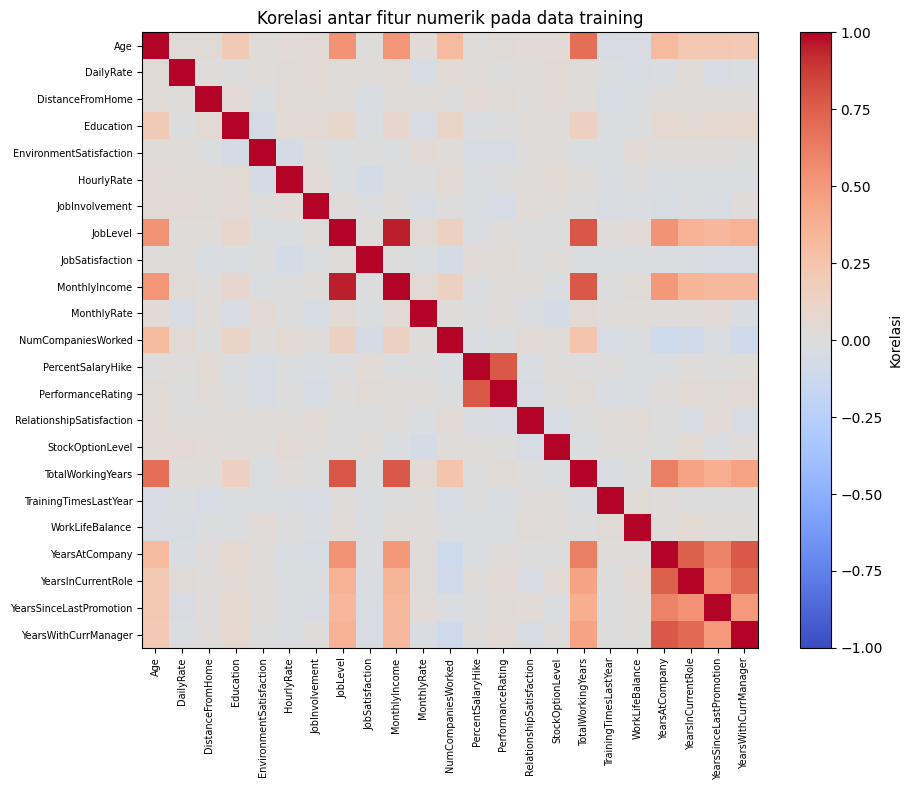

Pasangan dengan |korelasi| >= 0.70:


Korelasi
JobLevel           MonthlyIncome         0.947008
                   TotalWorkingYears     0.785244
YearsAtCompany     YearsWithCurrManager  0.776416
MonthlyIncome      TotalWorkingYears     0.774830
PercentSalaryHike  PerformanceRating     0.773922
YearsAtCompany     YearsInCurrentRole    0.747264
YearsInCurrentRole YearsWithCurrManager  0.706864

In [11]:
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
corr = X_train[numeric_cols].corr()
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Korelasi")
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=90, fontsize=7)
plt.yticks(range(len(numeric_cols)), numeric_cols, fontsize=7)
plt.title("Korelasi antar fitur numerik pada data training")
plt.tight_layout()
plt.show()

upper_triangle = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr = upper_triangle.stack()
print("Pasangan dengan |korelasi| >= 0.70:")
display(high_corr[high_corr.abs() >= 0.70].sort_values(key=abs, ascending=False).to_frame("Korelasi"))

### 8. Ringkasan temuan EDA

1. **Target tidak seimbang.** Pada data training (1.176 karyawan), 190 karyawan (16,16%) resign dan 986 (83,84%) bertahan. Model yang selalu menebak "bertahan" akan memperoleh accuracy sekitar 84% tanpa mendeteksi satu pun karyawan resign, sehingga F1, Recall, dan Precision dipakai sebagai metrik utama.
2. **Lembur menunjukkan perbedaan yang paling mencolok.** Persentase resign karyawan yang lembur adalah 28,53% (n=340), sedangkan yang tidak lembur 11,11% (n=836).
3. **Peran pekerjaan sangat bervariasi.** Sales Representative 41,67% (n=60), Laboratory Technician 26,98% (n=215), dan Human Resources 24,39% (n=41), sedangkan Research Director hanya 1,59% (n=63). Kategori dengan n kecil (Sales Representative, Human Resources) perlu ditafsirkan hati-hati.
4. **Status pernikahan dan perjalanan dinas.** Karyawan Single (25,47%, n=373) dan Travel_Frequently (25,33%, n=225) memiliki persentase resign lebih tinggi daripada kategori lainnya (Married 12,22%; Divorced 11,03%; Non-Travel 7,32%).
5. **Gender tidak menunjukkan perbedaan besar** (Male 16,90% vs Female 15,04%).
6. **Fitur numerik.** Rata-rata karyawan yang resign lebih muda (33,13 vs 37,74 tahun), bergaji lebih rendah (4.844 vs 6.872), memiliki pengalaman kerja lebih singkat (8,06 vs 12,00 tahun), dan masa kerja di perusahaan lebih pendek (4,90 vs 7,46 tahun). Jarak rumah ke tempat kerja sedikit lebih jauh (10,97 vs 9,05).
7. **Outlier dan skewness.** Pada fitur kontinu, outlier terbanyak ada pada `MonthlyIncome` (86), `YearsSinceLastPromotion` (85), dan `TotalWorkingYears` (52), semuanya miring ke kanan (skewness 1,1–2,0). Hal ini wajar untuk data gaji dan masa kerja, sehingga outlier **tidak dihapus**; `LogMonthlyIncome` dibuat pada tahap feature engineering untuk mengurangi skewness gaji.
8. **Multikolinearitas.** Tujuh pasangan fitur memiliki |r| ≥ 0,70, yang tertinggi `JobLevel`–`MonthlyIncome` (0,95). Fitur-fitur ini membawa informasi yang tumpang tindih dan dipertahankan pada Milestone 1; koefisien model linear untuk fitur yang berkorelasi hanya ditafsirkan sebagai arah pengaruh secara umum.

> Seluruh temuan di atas bersifat **asosiasi**, bukan hubungan sebab-akibat.

## E. Initial Feature Engineering (Bobot rubrik: 10)

Fitur turunan dibuat dari informasi pada baris karyawan yang sama. Tidak ada statistik yang dihitung dari seluruh dataset. Fitur baru diuji melalui perbandingan performa dengan fitur asli; peningkatan tidak diasumsikan terjadi sebelum eksperimen.

In [12]:
def add_features(data):
    data = data.copy()
    data["IncomePerExpYear"] = data["MonthlyIncome"] / (data["TotalWorkingYears"] + 1)
    data["TenureRatio"] = data["YearsAtCompany"] / (data["TotalWorkingYears"] + 1)
    data["PromotionGapRatio"] = data["YearsSinceLastPromotion"] / (data["YearsAtCompany"] + 1)
    data["AvgYearsPerCompany"] = data["TotalWorkingYears"] / (data["NumCompaniesWorked"] + 1)
    data["LogMonthlyIncome"] = np.log1p(data["MonthlyIncome"].clip(lower=0))
    return data

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)

new_features = [c for c in X_train_fe.columns if c not in X_train.columns]
print("Fitur turunan yang dibuat:", new_features)
print("Jumlah fitur awal:", X_train.shape[1])
print("Jumlah fitur setelah feature engineering:", X_train_fe.shape[1])

Fitur turunan yang dibuat: ['IncomePerExpYear', 'TenureRatio', 'PromotionGapRatio', 'AvgYearsPerCompany', 'LogMonthlyIncome']
Jumlah fitur awal: 30
Jumlah fitur setelah feature engineering: 35


## F. Baseline dan kandidat model awal (Bobot rubrik: 20)

### 1. Baseline pembanding
`DummyClassifier` dengan strategi kelas mayoritas menjadi pembanding sederhana. Model kandidat diharapkan memberikan hasil yang lebih baik daripada baseline ini pada metrik yang relevan.

### 2. Baseline model dan kandidat
- **Baseline model:** Logistic Regression.
- **Kandidat:** Logistic Regression dengan `class_weight="balanced"`, KNN, Decision Tree, Random Forest, dan Gradient Boosting.
- Model menggunakan preprocessing di dalam `Pipeline`, sehingga scaler dan encoder di-fit hanya pada bagian training dari setiap fold.
- Parameter yang digunakan merupakan parameter awal, belum melalui hyperparameter tuning.

In [13]:
def make_preprocessor(X_reference):
    numeric_features = X_reference.select_dtypes(include="number").columns.tolist()
    categorical_features = X_reference.select_dtypes(exclude="number").columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "F1": make_scorer(f1_score, zero_division=0),
    "Recall": make_scorer(recall_score, zero_division=0),
    "Precision": make_scorer(precision_score, zero_division=0),
    "ROC-AUC": "roc_auc"
}

def evaluate_model(name, estimator, X_data, y_data, feature_set):
    pipeline = Pipeline([
        ("preprocessing", make_preprocessor(X_data)),
        ("model", estimator)
    ])
    start = time.time()
    scores = cross_validate(
        pipeline, X_data, y_data, cv=cv, scoring=scoring,
        return_train_score=True, n_jobs=-1
    )

    row = {
        "Model": name,
        "Fitur": feature_set,
        "Waktu CV (detik)": round(time.time() - start, 2)
    }
    for metric in ["F1", "Recall", "Precision", "ROC-AUC"]:
        values = scores[f"test_{metric}"]
        row[metric] = f"{values.mean():.3f} ± {values.std():.3f}"
        row[f"{metric}_mean"] = values.mean()

    train_f1 = scores["train_F1"].mean()
    cv_f1 = scores["test_F1"].mean()
    row["F1 train"] = round(train_f1, 3)
    row["Gap F1 (train - CV)"] = round(train_f1 - cv_f1, 3)
    return row

models = {
    "Dummy (mayoritas)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "LR + class_weight": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "KNN (k=15)": KNeighborsClassifier(n_neighbors=15),
    "Decision Tree (depth=5)": DecisionTreeClassifier(
        max_depth=5, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

baseline_results = pd.DataFrame([
    evaluate_model(name, estimator, X_train, y_train, "Fitur asli")
    for name, estimator in models.items()
])

display_cols = [
    "Model", "Fitur", "F1", "Recall", "Precision", "ROC-AUC",
    "F1 train", "Gap F1 (train - CV)", "Waktu CV (detik)"
]
display(baseline_results[display_cols])

,Model,Fitur,F1,Recall,Precision,ROC-AUC,F1 train,Gap F1 (train - CV),Waktu CV (detik)
0,Dummy (mayoritas),Fitur asli,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.000,0.000,4.62
1,Logistic Regression,Fitur asli,0.561 ± 0.098,0.442 ± 0.096,0.776 ± 0.074,0.839 ± 0.029,0.612,0.051,0.61
2,LR + class_weight,Fitur asli,0.492 ± 0.034,0.737 ± 0.062,0.372 ± 0.038,0.827 ± 0.028,0.550,0.058,0.42
3,KNN (k=15),Fitur asli,0.058 ± 0.077,0.032 ± 0.042,0.400 ± 0.490,0.746 ± 0.057,0.118,0.060,0.53
4,Decision Tree (depth=5),Fitur asli,0.370 ± 0.085,0.305 ± 0.098,0.488 ± 0.045,0.666 ± 0.077,0.628,0.258,0.41
5,Random Forest,Fitur asli,0.321 ± 0.078,0.205 ± 0.065,0.872 ± 0.138,0.815 ± 0.034,1.000,0.679,6.00
6,Gradient Boosting,Fitur asli,0.451 ± 0.075,0.332 ± 0.072,0.731 ± 0.085,0.813 ± 0.016,0.897,0.445,2.96


### 2b. Diagnosis perilaku model dan regularisasi Random Forest

Sel berikut menghitung berapa banyak kasus resign yang benar-benar diprediksi oleh tiap model (prediksi out-of-fold pada data training), serta menguji apakah pembatasan kompleksitas dapat mengurangi overfitting Random Forest. Hasil ini menjadi dasar interpretasi pada bagian H.2.

In [14]:
print(f"Jumlah aktual resign pada data training: {int(y_train.sum())}\n")
diag_rows = []
for name in ["Logistic Regression", "LR + class_weight", "KNN (k=15)",
             "Random Forest", "Gradient Boosting"]:
    pipe = Pipeline([
        ("preprocessing", make_preprocessor(X_train)),
        ("model", models[name])
    ])
    pred = cross_val_predict(pipe, X_train, y_train, cv=cv, n_jobs=-1)
    diag_rows.append({
        "Model": name,
        "Diprediksi Yes": int(pred.sum()),
        "Yes yang tertangkap (TP)": int(((pred == 1) & (y_train == 1)).sum()),
        "Alarm palsu (FP)": int(((pred == 1) & (y_train == 0)).sum()),
        "Yes yang terlewat (FN)": int(((pred == 0) & (y_train == 1)).sum()),
    })
display(pd.DataFrame(diag_rows))

rf_reg = RandomForestClassifier(
    n_estimators=300, max_depth=8, min_samples_leaf=5,
    class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1
)
rf_reg_result = evaluate_model("RF (regularisasi)", rf_reg, X_train, y_train, "Fitur asli")
display(pd.DataFrame([rf_reg_result])[display_cols])

Jumlah aktual resign pada data training: 190



,Model,Diprediksi Yes,Yes yang tertangkap (TP),Alarm palsu (FP),Yes yang terlewat (FN)
0,Logistic Regression,107,84,23,106
1,LR + class_weight,380,140,240,50
2,KNN (k=15),6,6,0,184
3,Random Forest,48,39,9,151
4,Gradient Boosting,87,63,24,127


,Model,Fitur,F1,Recall,Precision,ROC-AUC,F1 train,Gap F1 (train - CV),Waktu CV (detik)
0,RF (regularisasi),Fitur asli,0.464 ± 0.092,0.395 ± 0.114,0.595 ± 0.064,0.802 ± 0.034,0.869,0.405,7.79


### 3. Confusion matrix untuk model utama
Confusion matrix dihitung menggunakan prediksi out-of-fold pada data training. Baris menunjukkan kelas aktual dan kolom menunjukkan kelas prediksi. Perhatikan False Negative (karyawan resign yang terlewat) dan False Positive (karyawan yang diprediksi resign tetapi sebenarnya bertahan).

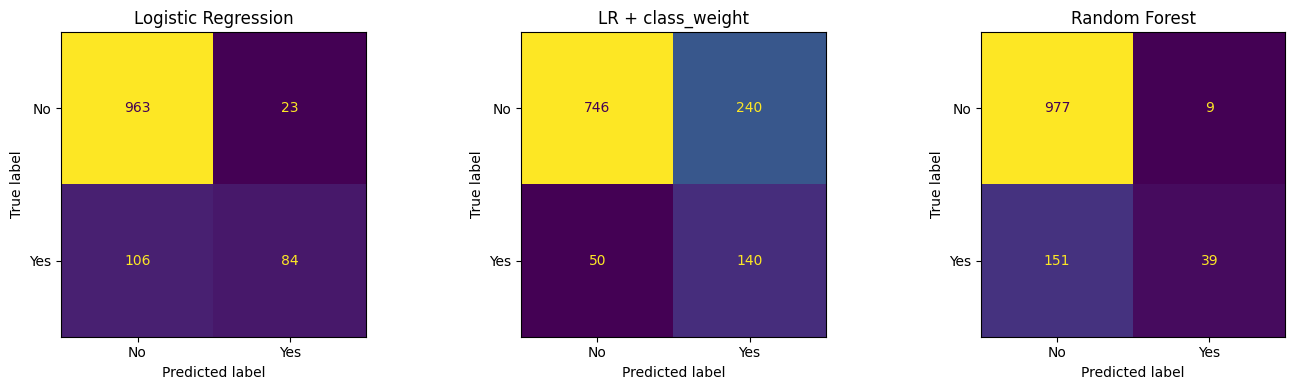

In [15]:
selected_models = ["Logistic Regression", "LR + class_weight", "Random Forest"]
fig, axes = plt.subplots(1, len(selected_models), figsize=(14, 4))
for ax, model_name in zip(axes, selected_models):
    pipeline = Pipeline([
        ("preprocessing", make_preprocessor(X_train)),
        ("model", models[model_name])
    ])
    oof_pred = cross_val_predict(pipeline, X_train, y_train, cv=cv, n_jobs=-1)
    ConfusionMatrixDisplay(
        confusion_matrix(y_train, oof_pred),
        display_labels=["No", "Yes"]
    ).plot(ax=ax, colorbar=False)
    ax.set_title(model_name)
plt.tight_layout()
plt.show()

### 4. Perbandingan dampak feature engineering
Model yang sama diuji pada fitur asli dan fitur asli + fitur turunan dengan skema Stratified 5-Fold CV yang sama.

In [16]:
fe_rows = []
for model_name in ["Logistic Regression", "LR + class_weight", "Random Forest"]:
    estimator = models[model_name]
    fe_rows.append(evaluate_model(model_name, estimator, X_train, y_train, "Fitur asli"))
    fe_rows.append(evaluate_model(model_name, estimator, X_train_fe, y_train, "Fitur asli + turunan"))

feature_results = pd.DataFrame(fe_rows)
display(feature_results[display_cols])

,Model,Fitur,F1,Recall,Precision,ROC-AUC,F1 train,Gap F1 (train - CV),Waktu CV (detik)
0,Logistic Regression,Fitur asli,0.561 ± 0.098,0.442 ± 0.096,0.776 ± 0.074,0.839 ± 0.029,0.612,0.051,0.41
1,Logistic Regression,Fitur asli + turunan,0.589 ± 0.058,0.479 ± 0.065,0.775 ± 0.070,0.847 ± 0.030,0.664,0.075,0.41
2,LR + class_weight,Fitur asli,0.492 ± 0.034,0.737 ± 0.062,0.372 ± 0.038,0.827 ± 0.028,0.550,0.058,0.46
3,LR + class_weight,Fitur asli + turunan,0.501 ± 0.039,0.732 ± 0.077,0.384 ± 0.040,0.836 ± 0.031,0.565,0.065,0.46
4,Random Forest,Fitur asli,0.321 ± 0.078,0.205 ± 0.065,0.872 ± 0.138,0.815 ± 0.034,1.000,0.679,8.93
5,Random Forest,Fitur asli + turunan,0.328 ± 0.060,0.211 ± 0.050,0.811 ± 0.096,0.809 ± 0.027,1.000,0.672,6.27


### 5. Analisis tambahan: threshold keputusan dan koefisien Logistic Regression

Analisis ini hanya memakai **data training** (prediksi out-of-fold), sehingga data test tetap tidak tersentuh.

- **Threshold keputusan.** Logistic Regression menghasilkan probabilitas resign; threshold bawaan 0,5 belum tentu optimal pada data yang tidak seimbang. Tabel berikut memperlihatkan perubahan Precision, Recall, dan F1 pada beberapa nilai threshold.
- **Koefisien.** Koefisien Logistic Regression menunjukkan arah asosiasi tiap fitur terhadap attrition. Karena terdapat fitur yang berkorelasi tinggi, koefisien ditafsirkan sebagai arah pengaruh secara umum, bukan besaran pasti per fitur.

In [17]:
from sklearn.metrics import precision_recall_curve

pipe_lr = Pipeline([
    ("preprocessing", make_preprocessor(X_train_fe)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
proba = cross_val_predict(pipe_lr, X_train_fe, y_train, cv=cv,
                          method="predict_proba", n_jobs=-1)[:, 1]

rows = []
for t in [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]:
    pred = (proba >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Diprediksi Yes": int(pred.sum()),
        "Precision": precision_score(y_train, pred, zero_division=0),
        "Recall": recall_score(y_train, pred),
        "F1": f1_score(y_train, pred, zero_division=0),
    })
threshold_df = pd.DataFrame(rows).round(3)
display(threshold_df)

prec, rec, thr = precision_recall_curve(y_train, proba)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
print(f"Threshold dengan F1 tertinggi (OOF training): {thr[f1s.argmax()]:.3f} | F1 = {f1s.max():.3f}")

,Threshold,Diprediksi Yes,Precision,Recall,F1
0,0.15,381,0.378,0.758,0.504
1,0.20,315,0.435,0.721,0.543
2,0.25,260,0.504,0.689,0.582
3,0.30,222,0.554,0.647,0.597
4,0.35,189,0.624,0.621,0.623
5,0.40,160,0.681,0.574,0.623
6,0.50,118,0.771,0.479,0.591


Threshold dengan F1 tertinggi (OOF training): 0.387 | F1 = 0.643


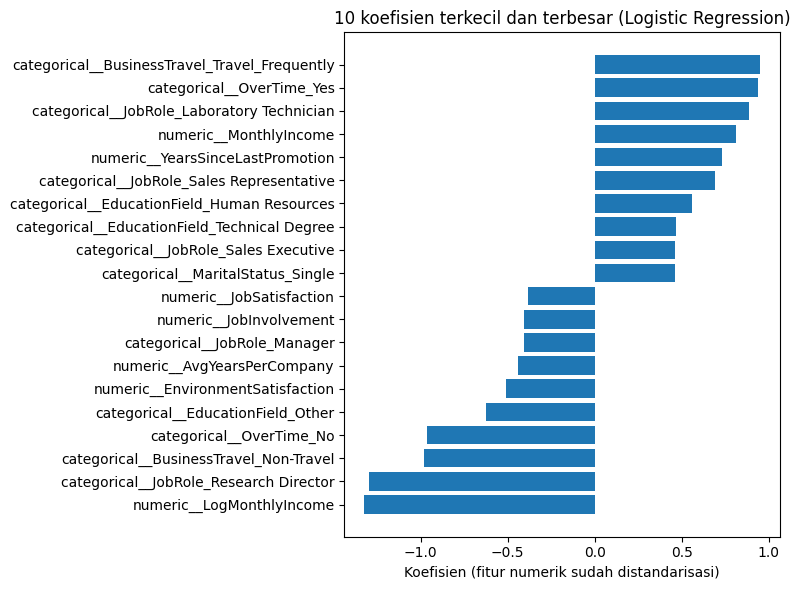

In [18]:
pipe_lr.fit(X_train_fe, y_train)
feat_names = pipe_lr.named_steps["preprocessing"].get_feature_names_out()
coef = pd.Series(pipe_lr.named_steps["model"].coef_[0], index=feat_names).sort_values()

top = pd.concat([coef.head(10), coef.tail(10)])
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values)
ax.set_title("10 koefisien terkecil dan terbesar (Logistic Regression)")
ax.set_xlabel("Koefisien (fitur numerik sudah distandarisasi)")
plt.tight_layout()
plt.show()

## G. Rancangan Evaluasi (Bobot rubrik: 10)

1. **Hold-out:** data dibagi secara stratified menjadi 80% training dan 20% testing. Data testing tidak digunakan dalam EDA, pemilihan model, atau tuning pada Milestone 1.
2. **Validasi model:** Stratified 5-Fold Cross-Validation dilakukan pada data training agar proporsi kelas relatif terjaga di setiap fold.
3. **Metrik utama:** F1-score dan Recall untuk kelas positif (`Attrition = Yes`).
4. **Metrik pendukung:** Precision dan ROC-AUC.
5. **Alasan pemilihan:** Recall mengukur proporsi karyawan resign yang berhasil ditemukan; Precision mengukur ketepatan prediksi resign; F1 menyeimbangkan Precision dan Recall; ROC-AUC mengukur kemampuan pemeringkatan kelas pada berbagai threshold.
6. **Pencegahan data leakage:** imputasi, scaling, dan one-hot encoding berada di dalam pipeline yang di-fit ulang pada setiap fold. Data test tetap disimpan untuk evaluasi akhir.

## H. Hasil Awal dan Analisis (Bobot rubrik: 5)

### 1. Perbandingan model
Tabel berikut dibuat langsung dari hasil eksperimen di bagian F.

In [19]:
summary_models = baseline_results.sort_values("F1_mean", ascending=False).copy()
display(summary_models[[
    "Model", "F1", "Recall", "Precision", "ROC-AUC",
    "F1 train", "Gap F1 (train - CV)"
]])

best_f1 = baseline_results.loc[baseline_results["F1_mean"].idxmax()]
best_recall = baseline_results.loc[baseline_results["Recall_mean"].idxmax()]

print("Model dengan F1 tertinggi:", best_f1["Model"], "| F1 =", round(best_f1["F1_mean"], 3))
print("Model dengan Recall tertinggi:", best_recall["Model"], "| Recall =", round(best_recall["Recall_mean"], 3))

,Model,F1,Recall,Precision,ROC-AUC,F1 train,Gap F1 (train - CV)
1,Logistic Regression,0.561 ± 0.098,0.442 ± 0.096,0.776 ± 0.074,0.839 ± 0.029,0.612,0.051
2,LR + class_weight,0.492 ± 0.034,0.737 ± 0.062,0.372 ± 0.038,0.827 ± 0.028,0.550,0.058
6,Gradient Boosting,0.451 ± 0.075,0.332 ± 0.072,0.731 ± 0.085,0.813 ± 0.016,0.897,0.445
4,Decision Tree (depth=5),0.370 ± 0.085,0.305 ± 0.098,0.488 ± 0.045,0.666 ± 0.077,0.628,0.258
5,Random Forest,0.321 ± 0.078,0.205 ± 0.065,0.872 ± 0.138,0.815 ± 0.034,1.000,0.679
3,KNN (k=15),0.058 ± 0.077,0.032 ± 0.042,0.400 ± 0.490,0.746 ± 0.057,0.118,0.060
0,Dummy (mayoritas),0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.000,0.000


Model dengan F1 tertinggi: Logistic Regression | F1 = 0.561
Model dengan Recall tertinggi: LR + class_weight | Recall = 0.737


### 2. Interpretasi hasil

**a. Perbandingan dengan baseline.** Dummy (mayoritas) memperoleh F1 = 0,000, Recall = 0,000, dan ROC-AUC = 0,500 karena tidak pernah memprediksi karyawan resign. Logistic Regression mencapai F1 = 0,561, Recall = 0,442, dan ROC-AUC = 0,839. Peningkatan ini menunjukkan bahwa model benar-benar menangkap pola dari data, bukan hanya mengikuti kelas mayoritas.

**b. Trade-off class_weight.** Logistic Regression biasa memiliki Precision tinggi (0,776) tetapi Recall rendah (0,442). Pada prediksi out-of-fold, model ini menandai 107 karyawan sebagai resign, 84 di antaranya benar, namun 106 dari 190 karyawan resign terlewat. Dengan `class_weight="balanced"`, Recall naik menjadi 0,737 (140 dari 190 tertangkap), tetapi model menandai 380 karyawan dan 240 di antaranya alarm palsu, sehingga Precision turun menjadi 0,372 dan F1 menjadi 0,492. Pilihan di antara keduanya bergantung pada biaya bisnis: jika kehilangan karyawan jauh lebih mahal daripada intervensi yang salah sasaran, LR + class_weight lebih sesuai.

**c. Overfitting pada model berbasis pohon.** Random Forest memiliki F1 train 1,000 tetapi F1 CV hanya 0,321 (gap 0,679), dan Gradient Boosting memiliki gap 0,445. Keduanya menghafal data training. Selain itu, keduanya sangat konservatif terhadap kelas minoritas: Random Forest hanya memprediksi 48 karyawan resign (151 dari 190 kasus terlewat), dan Gradient Boosting 87 (127 terlewat). Dengan parameter default dan hanya 190 sampel kelas positif pada data training, wajar jika Logistic Regression yang lebih sederhana (gap 0,051) mengungguli keduanya.

**d. Kegagalan KNN pada kelas minoritas.** KNN (k=15) hanya memprediksi 6 karyawan resign dari 190 kasus aktual (184 terlewat), sehingga F1 hanya 0,058 dan Recall 0,032. Pada data yang 83,8% berisi kelas mayoritas, tetangga terdekat hampir selalu didominasi kelas "bertahan". Hal ini juga menjelaskan simpangan Precision yang sangat besar (±0,490): pada beberapa fold KNN tidak membuat prediksi positif sama sekali, sehingga Precision fold tersebut bernilai 0.

**e. Dampak feature engineering.** F1 Logistic Regression naik dari 0,561 menjadi 0,589 (+0,028), LR + class_weight dari 0,492 menjadi 0,501, dan Random Forest dari 0,321 menjadi 0,328. Kenaikan ini lebih kecil daripada simpangan baku antar-fold (±0,058 hingga ±0,098), sehingga belum dapat disimpulkan bahwa fitur turunan benar-benar meningkatkan performa. Konsistensi arah pada ketiga model hanya menjadi indikasi awal yang perlu diuji lebih lanjut.

**f. Pengaruh regularisasi Random Forest.** Untuk menguji apakah overfitting dapat dikurangi, dicoba Random Forest dengan `max_depth=8`, `min_samples_leaf=5`, dan `class_weight="balanced_subsample"`. Gap F1 turun dari 0,679 menjadi 0,405, F1 naik dari 0,321 menjadi 0,464, dan Recall naik dari 0,205 menjadi 0,395, namun Precision turun dari 0,872 menjadi 0,595. ROC-AUC tidak membaik (0,815 menjadi 0,802), sehingga peningkatan F1 terutama berasal dari pergeseran keputusan akibat `class_weight`, bukan dari kemampuan memisahkan kelas yang lebih baik. Gap 0,405 masih besar dan F1 masih di bawah Logistic Regression (0,561), sehingga Random Forest belum menjadi kandidat utama dan perlu dituning lebih lanjut pada tahap pasca-UTS.

In [20]:
fe_comparison = feature_results.pivot(
    index="Model", columns="Fitur", values=["F1_mean", "Recall_mean"]
)
display(fe_comparison)

if {"Fitur asli", "Fitur asli + turunan"}.issubset(
    set(feature_results["Fitur"].unique())
):
    print("Perubahan F1 setelah feature engineering:")
    for model_name in ["Logistic Regression", "LR + class_weight", "Random Forest"]:
        part = feature_results[feature_results["Model"] == model_name].set_index("Fitur")
        before = part.loc["Fitur asli", "F1_mean"]
        after = part.loc["Fitur asli + turunan", "F1_mean"]
        print(f"{model_name}: {before:.3f} -> {after:.3f} (perubahan {after-before:+.3f})")

F1_mean                      Recall_mean  \
Fitur               Fitur asli Fitur asli + turunan  Fitur asli   
Model                                                             
LR + class_weight     0.492471             0.500887    0.736842   
Logistic Regression   0.561011             0.588927    0.442105   
Random Forest         0.321457             0.328483    0.205263   

                                          
Fitur               Fitur asli + turunan  
Model                                     
LR + class_weight               0.731579  
Logistic Regression             0.478947  
Random Forest                   0.210526

Perubahan F1 setelah feature engineering:
Logistic Regression: 0.561 -> 0.589 (perubahan +0.028)
LR + class_weight: 0.492 -> 0.501 (perubahan +0.008)
Random Forest: 0.321 -> 0.328 (perubahan +0.007)


### 3. Keterbatasan hasil awal
1. Hasil masih menggunakan parameter awal dan belum melalui hyperparameter tuning.
2. Kelas attrition lebih sedikit daripada kelas bertahan; metrik perlu dibaca dengan mempertimbangkan ketidakseimbangan kelas.
3. Dataset merupakan dataset HR yang tersedia untuk analisis dan belum tentu mewakili seluruh kondisi perusahaan nyata.
4. Hasil cross-validation merupakan estimasi awal; performa akhir pada data test belum dilaporkan pada Milestone 1.
5. Feature engineering perlu dinilai dari hasil perbandingan, bukan dari asumsi bahwa fitur baru pasti meningkatkan performa.

### 4. Kesimpulan sementara

Berdasarkan validasi silang pada data training, **Logistic Regression dengan fitur asli + turunan** dipilih sebagai kandidat utama (F1 0,589; Precision 0,775; ROC-AUC 0,847; gap overfitting kecil 0,075). Fitur turunan dipertahankan karena arah peningkatannya konsisten pada ketiga model yang diuji, meskipun besarnya belum melampaui variasi antar-fold. **Logistic Regression + class_weight** dipertahankan sebagai alternatif apabila prioritasnya menangkap sebanyak mungkin karyawan yang berpotensi resign (Recall 0,732, dengan konsekuensi Precision yang rendah).

Random Forest dan Gradient Boosting belum direkomendasikan karena overfitting dan Recall rendah; regularisasi sederhana mengurangi gap (0,679 → 0,405) tetapi belum melampaui Logistic Regression, sehingga keduanya layak dituning pasca-UTS. KNN tidak dilanjutkan karena hampir tidak mendeteksi kelas resign.

Berdasarkan EDA, faktor yang berasosiasi dengan attrition antara lain lembur, peran pekerjaan, status single, frekuensi perjalanan dinas, serta usia dan pendapatan yang lebih rendah (asosiasi, bukan sebab-akibat). Evaluasi pada data test belum dilakukan dan baru dijalankan satu kali setelah pemilihan model dan tuning selesai.

## I. Dokumentasi dan Rencana Pasca-UTS

### 1. Dokumentasi eksperimen
- **Sumber data:** IBM HR Analytics Employee Attrition & Performance (Kaggle), file `WA_Fn-UseC_-HR-Employee-Attrition.csv`.
- **Reproduksibilitas:** `RANDOM_STATE = 42` digunakan pada pembagian data, cross-validation, dan model; notebook dijalankan dari awal sampai akhir.
- **Konsistensi laporan:** angka pada laporan PDF berasal dari tabel hasil eksperimen di notebook ini.
- **Lingkungan eksekusi:** versi library dicetak pada sel di bawah.

In [21]:
import sys, sklearn
print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)

Python      : 3.13.18
pandas      : 2.2.3
numpy       : 2.4.6
scikit-learn: 1.6.1


### 2. Rencana setelah UTS
1. Melakukan hyperparameter tuning pada kandidat yang menjanjikan menggunakan `GridSearchCV` atau `RandomizedSearchCV`.
2. Memperdalam threshold tuning (eksplorasi awal pada bagian F.5 memakai prediksi out-of-fold data training) dan menetapkan threshold final berdasarkan kebutuhan bisnis.
3. Menguji teknik penanganan class imbalance, misalnya class weighting atau SMOTE. Jika SMOTE digunakan, proses harus ditempatkan di dalam pipeline cross-validation agar tidak terjadi data leakage.
4. Memperdalam interpretasi fitur (eksplorasi awal koefisien Logistic Regression pada bagian F.5) dengan feature importance model berbasis pohon dan analisis tambahan seperti SHAP.
5. Memilih model akhir berdasarkan metrik dan kebutuhan masalah.
6. Setelah pemilihan model dan tuning selesai, melakukan evaluasi satu kali pada data test yang telah disimpan.
7. Menyelesaikan laporan PDF dan menyiapkan presentasi berdasarkan hasil yang benar-benar diperoleh.